In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized/cardboard/cardboard1.jpg
/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized/cardboard/cardboard10.jpg
/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized/cardboard/cardboard100.jpg
/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized/cardboard/cardboard101.jpg
/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized/cardboard/cardboard102.jpg
/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized/cardboard/cardboard103.jpg
/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized/cardboard/cardboard104.jpg
/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized/cardboard/cardboard105.jpg
/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized/cardboard/cardboard106.jpg
/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized/cardboard/cardboard107.jpg
/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized/cardboard/cardboard108.jpg
/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resize

In [2]:
import os

DATA_DIR = "/kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized"

if os.path.exists(DATA_DIR):
    print("✅ TrashNet dataset is connected!")

    print("\nClasses:")
    print(os.listdir(DATA_DIR))

else:
    print("Dataset path not found.")
    print("Available Kaggle inputs:")
    print(os.listdir("/kaggle/input"))

✅ TrashNet dataset is connected!

Classes:
['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']


Create train , validate , test datasets

In [3]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import os
import random
import copy
import time
import gc

from torchvision import datasets, transforms, models

from torch.utils.data import DataLoader, Subset

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("✅ All required libraries imported successfully.")

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

✅ All required libraries imported successfully.
PyTorch: 2.11.0+cu130
GPU available: True


In [4]:
import numpy as np
import random
import torch

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("✅ SEED defined:", SEED)

✅ SEED defined: 42


In [5]:
import os
import numpy as np
import random
import torch

from torchvision import datasets

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Automatically locate TrashNet
required_classes = {
    "cardboard", "glass", "metal",
    "paper", "plastic", "trash"
}

DATA_DIR = None

for root, dirs, files in os.walk("/kaggle/input"):

    if required_classes.issubset(set(dirs)):
        DATA_DIR = root
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "TrashNet image dataset not found. "
        "Please attach the actual dataset through Add Input."
    )

# Load dataset
base_dataset = datasets.ImageFolder(
    root=DATA_DIR
)

# Define class variables
class_names = base_dataset.classes
targets = np.array(base_dataset.targets)
num_classes = len(class_names)

print("✅ Dataset loaded successfully")
print("Dataset path:", DATA_DIR)
print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Total images:", len(base_dataset))
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

✅ Dataset loaded successfully
Dataset path: /kaggle/input/datasets/feyzazkefe/trashnet/dataset-resized
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of classes: 6
Total images: 2527
Device: GPU


In [6]:
TEST_FRACTION = 0.20
VALIDATION_FRACTION = 0.15
MAX_TEST_PER_CLASS = 100

rng = np.random.default_rng(SEED)

class_indices = {}

for class_id in range(num_classes):

    indices = np.where(
        targets == class_id
    )[0].copy()

    rng.shuffle(indices)

    class_indices[class_id] = indices


# Determine the same test sample count for every class
min_class_count = min(
    len(indices)
    for indices in class_indices.values()
)

TEST_PER_CLASS = min(
    MAX_TEST_PER_CLASS,
    int(min_class_count * TEST_FRACTION)
)

if TEST_PER_CLASS < 1:
    raise ValueError("Not enough images to create a test set.")


train_indices = []
val_indices = []
test_indices = []


for class_id in range(num_classes):

    indices = class_indices[class_id]

    # Balanced test samples
    class_test = indices[:TEST_PER_CLASS]

    remaining = indices[TEST_PER_CLASS:]

    # Validation samples from remaining images
    val_count = int(
        round(len(remaining) * VALIDATION_FRACTION)
    )

    class_val = remaining[:val_count]

    class_train = remaining[val_count:]

    train_indices.extend(class_train.tolist())
    val_indices.extend(class_val.tolist())
    test_indices.extend(class_test.tolist())


print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Test samples:", len(test_indices))
print("Test images per class:", TEST_PER_CLASS)


# Verify there is no data leakage
assert len(set(train_indices) & set(val_indices)) == 0
assert len(set(train_indices) & set(test_indices)) == 0
assert len(set(val_indices) & set(test_indices)) == 0

# Verify balanced test dataset
test_targets = targets[test_indices]

print("\nBalanced test distribution:")

for i, name in enumerate(class_names):

    count = np.sum(test_targets == i)

    print(f"{name:10s}: {count}")

    assert count == TEST_PER_CLASS


# Save exact indices for reproducibility
np.savez(
    "/kaggle/working/gwo_trashnet_split.npz",
    train_indices=np.array(train_indices),
    val_indices=np.array(val_indices),
    test_indices=np.array(test_indices)
)

print("\nDataset split successfully created.")

Training samples: 2012
Validation samples: 353
Test samples: 162
Test images per class: 27

Balanced test distribution:
cardboard : 27
glass     : 27
metal     : 27
paper     : 27
plastic   : 27
trash     : 27

Dataset split successfully created.


In [7]:
IMG_SIZE = 224

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]


train_transform = transforms.Compose([

    transforms.Resize((256, 256)),

    transforms.RandomResizedCrop(
        224,
        scale=(0.75, 1.0)
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=mean,
        std=std
    )
])


eval_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=mean,
        std=std
    )
])


train_dataset_full = datasets.ImageFolder(
    DATA_DIR,
    transform=train_transform
)

eval_dataset_full = datasets.ImageFolder(
    DATA_DIR,
    transform=eval_transform
)

assert (
    train_dataset_full.class_to_idx
    == eval_dataset_full.class_to_idx
)


train_dataset = Subset(
    train_dataset_full,
    train_indices
)

val_dataset = Subset(
    eval_dataset_full,
    val_indices
)

test_dataset = Subset(
    eval_dataset_full,
    test_indices
)


BATCH_SIZE = 32

pin = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=pin,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=pin
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=pin
)


print("Training loader:", len(train_loader))
print("Validation loader:", len(val_loader))
print("Test loader:", len(test_loader))

Training loader: 63
Validation loader: 12
Test loader: 6


**Calculate inverse-frequency class weigths**

In [8]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Selected device: cuda
GPU: Tesla T4


In [9]:
train_targets = targets[train_indices]

class_counts = np.bincount(
    train_targets,
    minlength=num_classes
)

N = len(train_targets)
K = num_classes

inverse_weights = N / (
    K * class_counts
)

inverse_class_weights = torch.tensor(
    inverse_weights,
    dtype=torch.float32
).to(device)


print("Inverse-frequency class weights:\n")

for class_name, count, weight in zip(
    class_names,
    class_counts,
    inverse_class_weights
):

    print(
        f"{class_name:10s} | "
        f"Images: {count:4d} | "
        f"Weight: {weight.item():.4f}"
    )

Inverse-frequency class weights:

cardboard  | Images:  320 | Weight: 1.0479
glass      | Images:  403 | Weight: 0.8321
metal      | Images:  326 | Weight: 1.0286
paper      | Images:  482 | Weight: 0.6957
plastic    | Images:  387 | Weight: 0.8665
trash      | Images:   94 | Weight: 3.5674


# Build the GWO-EfficientNet model

In [10]:
def create_gwo_efficientnet(dropout=0.3):

    model = models.efficientnet_b0(
        weights=models.EfficientNet_B0_Weights.DEFAULT
    )

    # Freeze the complete feature extractor
    for param in model.features.parameters():
        param.requires_grad = False

    # Unfreeze final four feature blocks
    for param in model.features[-4:].parameters():
        param.requires_grad = True

    num_features = (
        model.classifier[1].in_features
    )

    model.classifier = nn.Sequential(

        nn.Dropout(dropout),

        nn.Linear(
            num_features,
            256
        ),

        nn.ReLU(),

        nn.LayerNorm(256),

        nn.Dropout(dropout),

        nn.Linear(
            256,
            num_classes
        )
    )

    return model.to(device)

Train and evalulate function

In [11]:
def make_criterion():

    return nn.CrossEntropyLoss(
        weight=inverse_class_weights,
        label_smoothing=0.05
    )


def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    # Keep frozen feature blocks in evaluation mode
    for layer in model.features[:-4]:
        layer.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    return (
        total_loss / total,
        correct / total
    )


def evaluate_model(
    model,
    loader,
    criterion
):

    model.eval()

    total_loss = 0.0
    total = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels_device = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels_device
            )

            predictions = outputs.argmax(dim=1)

            total_loss += (
                loss.item() * images.size(0)
            )

            total += labels.size(0)

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    y_true = np.asarray(all_labels)
    y_pred = np.asarray(all_predictions)

    return {

        "loss": total_loss / total,

        "accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "macro_f1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        "y_true": y_true,
        "y_pred": y_pred
    }

# GWO

In [12]:
GWO_BOUNDS = np.array([

    # Classifier learning rate: 10^-4.5 to 10^-3
    [-4.5, -3.0],

    # Backbone learning rate: 10^-6 to 10^-4.3
    [-6.0, -4.3],

    # Dropout
    [0.20, 0.50],

    # Weight decay
    [-6.0, -3.5]

])


def decode_position(position):

    return {

        "classifier_lr": 10 ** position[0],

        "backbone_lr": 10 ** position[1],

        "dropout": position[2],

        "weight_decay": 10 ** position[3]

    }

**GWO fuction**

In [13]:
PROXY_EPOCHS = 3


def gwo_objective(position):

    params = decode_position(position)

    # Reset training randomness for a more consistent comparison
    random.seed(2026)
    torch.manual_seed(2026)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(2026)

    model = create_gwo_efficientnet(
        dropout=params["dropout"]
    )

    criterion = make_criterion()

    optimizer = torch.optim.AdamW(

        [

            {
                "params": model.features[-4:].parameters(),
                "lr": params["backbone_lr"]
            },

            {
                "params": model.classifier.parameters(),
                "lr": params["classifier_lr"]
            }

        ],

        weight_decay=params["weight_decay"]

    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=PROXY_EPOCHS,
        eta_min=1e-6
    )

    last_macro_f1 = 0.0

    for epoch in range(PROXY_EPOCHS):

        train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        val_results = evaluate_model(
            model,
            val_loader,
            criterion
        )

        last_macro_f1 = val_results["macro_f1"]

        scheduler.step()

    del model
    del optimizer

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return last_macro_f1

In [14]:
class GreyWolfOptimizer:

    def __init__(
        self,
        objective,
        bounds,
        n_wolves=4,
        n_iterations=3
    ):

        self.objective = objective
        self.bounds = np.asarray(bounds)

        self.n_wolves = n_wolves
        self.n_iterations = n_iterations

        self.dim = len(bounds)

        self.positions = np.random.uniform(
            self.bounds[:, 0],
            self.bounds[:, 1],
            size=(n_wolves, self.dim)
        )


    def optimize(self):

        best_position = None
        best_score = -np.inf

        history = []

        for iteration in range(self.n_iterations):

            print(
                f"\nGWO Iteration "
                f"{iteration+1}/{self.n_iterations}"
            )

            scores = []

            for i in range(self.n_wolves):

                score = self.objective(
                    self.positions[i].copy()
                )

                scores.append(score)

                print(
                    f"Wolf {i+1}: "
                    f"Validation Macro-F1 = {score:.4f}"
                )

            scores = np.asarray(scores)

            order = np.argsort(scores)[::-1]

            alpha = self.positions[order[0]].copy()
            beta = self.positions[order[1]].copy()
            delta = self.positions[order[2]].copy()

            if scores[order[0]] > best_score:

                best_score = scores[order[0]]
                best_position = alpha.copy()

            history.append({

                "iteration": iteration + 1,

                "best_validation_macro_f1": best_score

            })

            print(
                "Best Macro-F1:",
                round(best_score, 4)
            )

            a = 2 - (
                2 * iteration /
                max(1, self.n_iterations - 1)
            )

            new_positions = self.positions.copy()

            for i in range(self.n_wolves):

                for j in range(self.dim):

                    r1, r2 = np.random.rand(2)

                    A1 = 2 * a * r1 - a
                    C1 = 2 * r2

                    D1 = abs(
                        C1 * alpha[j]
                        - self.positions[i, j]
                    )

                    X1 = alpha[j] - A1 * D1


                    r1, r2 = np.random.rand(2)

                    A2 = 2 * a * r1 - a
                    C2 = 2 * r2

                    D2 = abs(
                        C2 * beta[j]
                        - self.positions[i, j]
                    )

                    X2 = beta[j] - A2 * D2


                    r1, r2 = np.random.rand(2)

                    A3 = 2 * a * r1 - a
                    C3 = 2 * r2

                    D3 = abs(
                        C3 * delta[j]
                        - self.positions[i, j]
                    )

                    X3 = delta[j] - A3 * D3


                    new_positions[i, j] = (
                        X1 + X2 + X3
                    ) / 3


            self.positions = np.clip(
                new_positions,
                self.bounds[:, 0],
                self.bounds[:, 1]
            )


        return (
            best_position,
            best_score,
            history
        )

In [15]:
np.random.seed(42)

gwo = GreyWolfOptimizer(

    objective=gwo_objective,

    bounds=GWO_BOUNDS,

    n_wolves=4,

    n_iterations=3
)


best_position, best_proxy_f1, gwo_history = gwo.optimize()

best_params = decode_position(best_position)


print("\n" + "=" * 55)
print("BEST GWO HYPERPARAMETERS")
print("=" * 55)

for key, value in best_params.items():

    print(
        f"{key}: {value:.7g}"
    )

print(
    "\nBest proxy validation Macro-F1:",
    round(best_proxy_f1, 4)
)


GWO Iteration 1/3
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 199MB/s]


Wolf 1: Validation Macro-F1 = 0.7818
Wolf 2: Validation Macro-F1 = 0.6758
Wolf 3: Validation Macro-F1 = 0.7792
Wolf 4: Validation Macro-F1 = 0.7701
Best Macro-F1: 0.7818

GWO Iteration 2/3
Wolf 1: Validation Macro-F1 = 0.8191
Wolf 2: Validation Macro-F1 = 0.7796
Wolf 3: Validation Macro-F1 = 0.7989
Wolf 4: Validation Macro-F1 = 0.8233
Best Macro-F1: 0.8233

GWO Iteration 3/3
Wolf 1: Validation Macro-F1 = 0.6562
Wolf 2: Validation Macro-F1 = 0.8244
Wolf 3: Validation Macro-F1 = 0.8189
Wolf 4: Validation Macro-F1 = 0.8318
Best Macro-F1: 0.8318

BEST GWO HYPERPARAMETERS
classifier_lr: 0.0003808431
backbone_lr: 5.011872e-05
dropout: 0.2
weight_decay: 0.0003162278

Best proxy validation Macro-F1: 0.8318


In [16]:
import json
with open(
    "/kaggle/working/gwo_best_parameters.json",
    "w"
) as f:

    json.dump(
        best_params,
        f,
        indent=4
    )

pd.DataFrame(gwo_history).to_csv(
    "/kaggle/working/gwo_search_history.csv",
    index=False
)

# Final model and fine tunning it

In [17]:


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    print(f"Random seed set to {seed}")

seed_everything(42)

Random seed set to 42


In [18]:
FINAL_EPOCHS = 30
PATIENCE = 7

seed_everything(42)

improved_gwo_inverse_model = create_gwo_efficientnet(
    dropout=best_params["dropout"]
)

criterion = make_criterion()


optimizer = torch.optim.AdamW(

    [

        {
            "params": improved_gwo_inverse_model.features[-4:].parameters(),
            "lr": best_params["backbone_lr"]
        },

        {
            "params": improved_gwo_inverse_model.classifier.parameters(),
            "lr": best_params["classifier_lr"]
        }

    ],

    weight_decay=best_params["weight_decay"]

)


scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=FINAL_EPOCHS,

    eta_min=1e-6

)


checkpoint_path = (
    "/kaggle/working/"
    "GWO_EfficientNet_Inverse_Final.pth"
)


best_val_f1 = -1.0

best_state = None

patience_counter = 0

training_history = []


for epoch in range(FINAL_EPOCHS):

    start_time = time.time()


    train_loss, train_acc = train_one_epoch(

        improved_gwo_inverse_model,

        train_loader,

        criterion,

        optimizer

    )


    val_results = evaluate_model(

        improved_gwo_inverse_model,

        val_loader,

        criterion

    )


    scheduler.step()


    training_history.append({

        "epoch": epoch + 1,

        "train_loss": train_loss,

        "train_accuracy": train_acc,

        "val_loss": val_results["loss"],

        "val_accuracy": val_results["accuracy"],

        "val_macro_f1": val_results["macro_f1"],

        "val_weighted_f1": val_results["weighted_f1"]

    })


    current_lr = optimizer.param_groups[1]["lr"]


    print(

        f"Epoch [{epoch+1:02d}/{FINAL_EPOCHS}] | "

        f"Train Acc: {train_acc*100:.2f}% | "

        f"Val Acc: {val_results['accuracy']*100:.2f}% | "

        f"Val Macro-F1: {val_results['macro_f1']:.4f} | "

        f"Val Loss: {val_results['loss']:.4f} | "

        f"LR: {current_lr:.2e} | "

        f"Time: {time.time()-start_time:.1f}s"

    )


    # Save best model based on validation Macro-F1
    if val_results["macro_f1"] > best_val_f1:

        best_val_f1 = val_results["macro_f1"]

        best_state = copy.deepcopy(
            improved_gwo_inverse_model.state_dict()
        )

        torch.save(
            best_state,
            checkpoint_path
        )

        patience_counter = 0

        print("  Best model saved.")

    else:

        patience_counter += 1


    if patience_counter >= PATIENCE:

        print("\nEarly stopping triggered.")

        break


if best_state is None:

    raise RuntimeError(
        "Training failed to produce a valid checkpoint."
    )


# Restore best validation model
improved_gwo_inverse_model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

improved_gwo_inverse_model.eval()


print("\nTraining completed.")
print(
    "Best validation Macro-F1:",
    round(best_val_f1, 4)
)

print(
    "Saved model:",
    checkpoint_path
)

Random seed set to 42
Epoch [01/30] | Train Acc: 62.62% | Val Acc: 78.47% | Val Macro-F1: 0.7608 | Val Loss: 0.8384 | LR: 3.80e-04 | Time: 14.3s
  Best model saved.
Epoch [02/30] | Train Acc: 83.55% | Val Acc: 85.27% | Val Macro-F1: 0.8350 | Val Loss: 0.7107 | LR: 3.77e-04 | Time: 14.5s
  Best model saved.
Epoch [03/30] | Train Acc: 87.43% | Val Acc: 85.55% | Val Macro-F1: 0.8396 | Val Loss: 0.7033 | LR: 3.72e-04 | Time: 14.1s
  Best model saved.
Epoch [04/30] | Train Acc: 91.55% | Val Acc: 86.97% | Val Macro-F1: 0.8486 | Val Loss: 0.6656 | LR: 3.64e-04 | Time: 14.0s
  Best model saved.
Epoch [05/30] | Train Acc: 93.49% | Val Acc: 86.40% | Val Macro-F1: 0.8478 | Val Loss: 0.6671 | LR: 3.55e-04 | Time: 13.9s
Epoch [06/30] | Train Acc: 94.68% | Val Acc: 89.24% | Val Macro-F1: 0.8837 | Val Loss: 0.6268 | LR: 3.45e-04 | Time: 14.1s
  Best model saved.
Epoch [07/30] | Train Acc: 96.27% | Val Acc: 89.52% | Val Macro-F1: 0.8925 | Val Loss: 0.6203 | LR: 3.32e-04 | Time: 13.9s
  Best model save

Plot training and validation curves

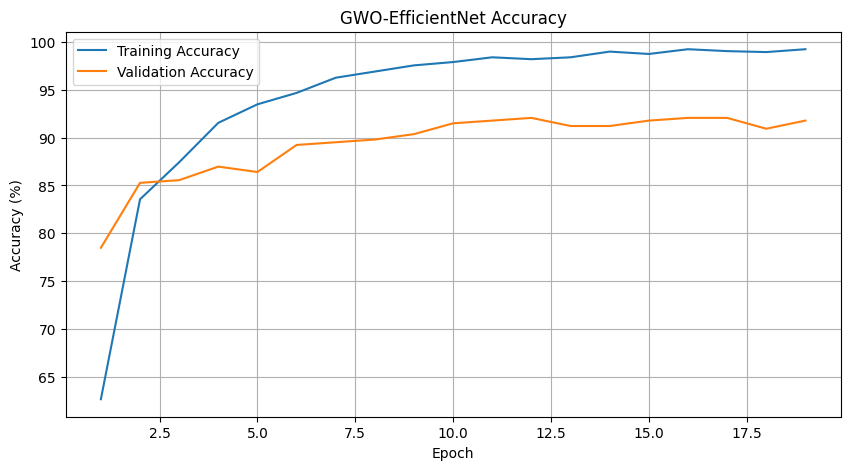

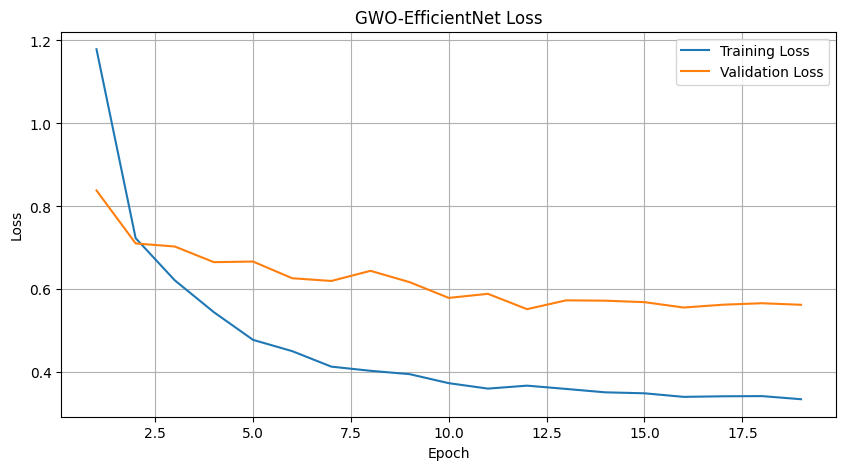

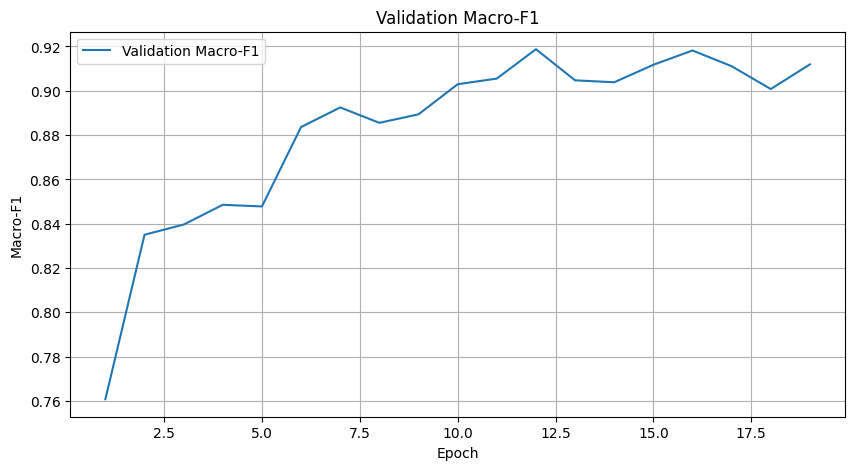

In [19]:
import matplotlib.pyplot as plt
history_df = pd.DataFrame(training_history)

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"] * 100,
    label="Training Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("GWO-EfficientNet Accuracy")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GWO-EfficientNet Loss")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("Validation Macro-F1")
plt.legend()
plt.grid()
plt.show()


history_df.to_csv(
    "/kaggle/working/GWO_EfficientNet_training_history.csv",
    index=False
)

# final test evaluation

In [20]:
test_results = evaluate_model(
    improved_gwo_inverse_model,
    test_loader,
    criterion
)

print("FINAL GWO-EFFICIENTNET RESULTS")

print(
    f"Test Accuracy: "
    f"{test_results['accuracy']*100:.2f}%"
)

print(
    f"Test Macro-F1: "
    f"{test_results['macro_f1']*100:.4f}"
)

print(
    f"Test Weighted-F1: "
    f"{test_results['weighted_f1']*100:.4f}"
)

FINAL GWO-EFFICIENTNET RESULTS
Test Accuracy: 85.80%
Test Macro-F1: 85.7282
Test Weighted-F1: 85.7282


In [21]:
print(
    classification_report(
        test_results["y_true"],
        test_results["y_pred"],
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

   cardboard     0.9231    0.8889    0.9057        27
       glass     0.8571    0.8889    0.8727        27
       metal     0.8333    0.9259    0.8772        27
       paper     0.8571    0.8889    0.8727        27
     plastic     0.8400    0.7778    0.8077        27
       trash     0.8400    0.7778    0.8077        27

    accuracy                         0.8580       162
   macro avg     0.8584    0.8580    0.8573       162
weighted avg     0.8584    0.8580    0.8573       162



In [22]:
# Save final model and metadata together
final_checkpoint = {

    "state_dict": improved_gwo_inverse_model.state_dict(),

    "class_names": class_names,

    "best_params": best_params,

    "inverse_class_weights": inverse_class_weights.cpu(),

    "best_validation_macro_f1": best_val_f1,

    "test_accuracy": test_results["accuracy"],

    "test_macro_f1": test_results["macro_f1"],

    "test_weighted_f1": test_results["weighted_f1"],

    "image_size": IMG_SIZE

}

torch.save(
    final_checkpoint,
    "/kaggle/working/GWO_EfficientNet_Inverse_Complete.pth"
)


results_df = pd.DataFrame([{

    "Model": "GWO-EfficientNet-B0 + Inverse Class Weights",

    "Accuracy (%)": test_results["accuracy"] * 100,

    "Macro-F1 (%)": test_results["macro_f1"] * 100,

    "Weighted-F1 (%)": test_results["weighted_f1"] * 100,

    "Best Validation Macro-F1": best_val_f1

}])


results_df.to_csv(
    "/kaggle/working/GWO_EfficientNet_Final_Results.csv",
    index=False
)


print("\nAll files saved successfully.")


All files saved successfully.


Checking which class is strugling

In [23]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
# Use the final GWO-trained model
model = improved_gwo_inverse_model
model.eval()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

y_true = []
y_pred = []

with torch.inference_mode():
    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

val_accuracy = accuracy_score(y_true, y_pred)
val_macro_f1 = f1_score(y_true, y_pred, average="macro")

print("VALIDATION RESULTS")
print(f"Accuracy  : {val_accuracy * 100:.2f}%")
print(f"Macro F1  : {val_macro_f1 * 100:.2f}%")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_true, y_pred))

print("\nBEST GWO PARAMETERS")
print(best_params)

VALIDATION RESULTS
Accuracy  : 92.07%
Macro F1  : 91.88%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   cardboard     1.0000    0.9107    0.9533        56
       glass     0.8701    0.9437    0.9054        71
       metal     0.8644    0.8947    0.8793        57
       paper     0.9756    0.9412    0.9581        85
     plastic     0.9231    0.8824    0.9023        68
       trash     0.8421    1.0000    0.9143        16

    accuracy                         0.9207       353
   macro avg     0.9126    0.9288    0.9188       353
weighted avg     0.9241    0.9207    0.9213       353


CONFUSION MATRIX
[[51  0  3  1  0  1]
 [ 0 67  3  0  1  0]
 [ 0  3 51  0  3  0]
 [ 0  0  2 80  1  2]
 [ 0  7  0  1 60  0]
 [ 0  0  0  0  0 16]]

BEST GWO PARAMETERS
{'classifier_lr': np.float64(0.00038084307819601733), 'backbone_lr': np.float64(5.011872336272725e-05), 'dropout': np.float64(0.2), 'weight_decay': np.float64(0.00031622776601683794)}


# Improving Model 

**By changing class weigths**

In [24]:

import torch.nn as nn

# Calculate softer inverse-frequency weights
soft_class_weights = torch.sqrt(
    inverse_class_weights.detach().clone()
)

# Normalize weights
soft_class_weights = (
    soft_class_weights / soft_class_weights.mean()
)

# Create new weighted loss
criterion = nn.CrossEntropyLoss(
    weight=soft_class_weights,
    label_smoothing=0.05
)

print("Original class weights:")
print(inverse_class_weights.cpu().numpy())

print("\nNew softer class weights:")
print(soft_class_weights.cpu().numpy())

Original class weights:
[1.0479167  0.83209264 1.0286299  0.6957123  0.8664944  3.567376  ]

New softer class weights:
[0.9300832  0.8287896  0.9214845  0.7578326  0.84574866 1.7160617 ]


**Expand the GWO search space**

In [25]:
bounds = np.array([
    [-4.5, -3.0],   # Classifier learning rate
    [-6.0, -4.0],   # Backbone learning rate
    [0.10, 0.45],   # Dropout
    [-6.0, -3.5]    # Weight decay
])

In [26]:
n_wolves = 5
n_iterations = 4

PROXY_EPOCHS = 5

**Fine-tune more EfficientNet layer**s

In [27]:
model = create_gwo_efficientnet(
    dropout=best_params["dropout"]
).to(device)

# Freeze all feature extraction layers
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the last six feature blocks
for block in model.features[-6:]:
    for param in block.parameters():
        param.requires_grad = True

# Keep the entire classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

print("Fine-tuning configuration:")
print("Trainable feature blocks: Last 6")

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Fine-tuning configuration:
Trainable feature blocks: Last 6
Trainable parameters: 4318448


# Final comparision

In [28]:
final_models = {}

candidate_models = {
    "Original GWO + Inverse Weights": "improved_gwo_inverse_model",
    "GWO + Softer Weights": "soft_weight_model",
    "Expanded GWO": "expanded_gwo_model",
    "EfficientNet - Last 6 Blocks": "six_block_model"
}

for model_name, variable_name in candidate_models.items():

    model_object = globals().get(variable_name)

    if isinstance(model_object, torch.nn.Module):
        final_models[model_name] = model_object
        print(f"Registered: {model_name}")
    else:
        print(f"Not available yet: {model_name}")

print("\nTotal models registered:", len(final_models))

Registered: Original GWO + Inverse Weights
Not available yet: GWO + Softer Weights
Not available yet: Expanded GWO
Not available yet: EfficientNet - Last 6 Blocks

Total models registered: 1


# Train softer weigth model

In [29]:
import torch
import torch.nn as nn
import copy
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# Reproducibility
seed_everything(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 1. Calculate softer class weights
soft_class_weights = torch.sqrt(
    inverse_class_weights.detach().clone()
)

soft_class_weights = (
    soft_class_weights / soft_class_weights.mean()
).to(device)

criterion_soft = nn.CrossEntropyLoss(
    weight=soft_class_weights,
    label_smoothing=0.05
)

# 2. Create a completely fresh model
soft_weight_model = create_gwo_efficientnet(
    dropout=float(best_params["dropout"])
).to(device)

# Freeze all feature layers
for param in soft_weight_model.features.parameters():
    param.requires_grad = False

# Unfreeze last four feature blocks
for block in soft_weight_model.features[-4:]:
    for param in block.parameters():
        param.requires_grad = True

# Keep classifier trainable
for param in soft_weight_model.classifier.parameters():
    param.requires_grad = True

# 3. AdamW optimizer with separate learning rates
optimizer_soft = torch.optim.AdamW(
    [
        {
            "params": soft_weight_model.features[-4:].parameters(),
            "lr": float(best_params["backbone_lr"])
        },
        {
            "params": soft_weight_model.classifier.parameters(),
            "lr": float(best_params["classifier_lr"])
        }
    ],
    weight_decay=float(best_params["weight_decay"])
)

# 4. Cosine learning-rate scheduler
scheduler_soft = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_soft,
    T_max=30,
    eta_min=1e-7
)

# 5. Training and evaluation function
def run_soft_epoch(model, loader, training=False):

    model.train() if training else model.eval()

    total_loss = 0
    y_true = []
    y_pred = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer_soft.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            outputs = model(images)
            loss = criterion_soft(outputs, labels)

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), 1.0
                )

                optimizer_soft.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")

    return avg_loss, accuracy, macro_f1


# 6. Final training with early stopping
FINAL_EPOCHS = 30
PATIENCE = 7

best_soft_f1 = 0
patience_counter = 0

soft_history = {
    "train_loss": [],
    "val_loss": [],
    "train_f1": [],
    "val_f1": []
}

for epoch in range(FINAL_EPOCHS):

    train_loss, train_acc, train_f1 = run_soft_epoch(
        soft_weight_model,
        train_loader,
        training=True
    )

    val_loss, val_acc, val_f1 = run_soft_epoch(
        soft_weight_model,
        val_loader,
        training=False
    )

    scheduler_soft.step()

    soft_history["train_loss"].append(train_loss)
    soft_history["val_loss"].append(val_loss)
    soft_history["train_f1"].append(train_f1)
    soft_history["val_f1"].append(val_f1)

    print(
        f"Epoch [{epoch+1}/{FINAL_EPOCHS}] "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Val Macro-F1: {val_f1*100:.2f}%"
    )

    if val_f1 > best_soft_f1:

        best_soft_f1 = val_f1
        patience_counter = 0

        torch.save(
            soft_weight_model.state_dict(),
            "/kaggle/working/soft_weight_best.pth"
        )

    else:

        patience_counter += 1

    if patience_counter >= PATIENCE:

        print("Early stopping triggered.")
        break


# 7. Load best checkpoint
soft_weight_model.load_state_dict(
    torch.load(
        "/kaggle/working/soft_weight_best.pth",
        map_location=device,
        weights_only=True
    )
)

soft_weight_model.eval()

print("\nSOFTER WEIGHT MODEL TRAINING COMPLETED")
print(f"Best Validation Macro-F1: {best_soft_f1*100:.2f}%")

Random seed set to 42
Epoch [1/30] Train Acc: 62.38% | Val Acc: 79.04% | Val Macro-F1: 74.27%
Epoch [2/30] Train Acc: 80.86% | Val Acc: 83.85% | Val Macro-F1: 79.43%
Epoch [3/30] Train Acc: 84.49% | Val Acc: 85.27% | Val Macro-F1: 81.70%
Epoch [4/30] Train Acc: 88.62% | Val Acc: 88.10% | Val Macro-F1: 85.27%
Epoch [5/30] Train Acc: 90.95% | Val Acc: 86.40% | Val Macro-F1: 84.37%
Epoch [6/30] Train Acc: 92.35% | Val Acc: 88.67% | Val Macro-F1: 87.50%
Epoch [7/30] Train Acc: 94.09% | Val Acc: 90.37% | Val Macro-F1: 89.55%
Epoch [8/30] Train Acc: 94.63% | Val Acc: 88.95% | Val Macro-F1: 87.81%
Epoch [9/30] Train Acc: 94.83% | Val Acc: 89.80% | Val Macro-F1: 88.31%
Epoch [10/30] Train Acc: 96.67% | Val Acc: 91.50% | Val Macro-F1: 90.17%
Epoch [11/30] Train Acc: 96.97% | Val Acc: 90.65% | Val Macro-F1: 89.53%
Epoch [12/30] Train Acc: 96.42% | Val Acc: 90.08% | Val Macro-F1: 89.33%
Epoch [13/30] Train Acc: 96.92% | Val Acc: 90.65% | Val Macro-F1: 89.56%
Epoch [14/30] Train Acc: 97.86% | Val 

In [30]:
final_models["GWO + Softer Weights"] = soft_weight_model

print("Models currently available:")

for name in final_models:
    print("-", name)

Models currently available:
- Original GWO + Inverse Weights
- GWO + Softer Weights


# TRaining last 6 blocks of efficientNet

In [31]:

import copy
from sklearn.metrics import accuracy_score, f1_score

seed_everything(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 1. Create a fresh EfficientNet model
six_block_model = create_gwo_efficientnet(
    dropout=float(best_params["dropout"])
).to(device)

# 2. Freeze all feature layers
for param in six_block_model.features.parameters():
    param.requires_grad = False

# 3. Unfreeze the last six feature blocks
for block in six_block_model.features[-6:]:
    for param in block.parameters():
        param.requires_grad = True

# 4. Keep classifier trainable
for param in six_block_model.classifier.parameters():
    param.requires_grad = True

# 5. Use softer class weights
criterion_6 = nn.CrossEntropyLoss(
    weight=soft_class_weights,
    label_smoothing=0.05
)

# 6. AdamW optimizer
optimizer_6 = torch.optim.AdamW(
    [
        {
            "params": six_block_model.features[-6:].parameters(),
            "lr": float(best_params["backbone_lr"])
        },
        {
            "params": six_block_model.classifier.parameters(),
            "lr": float(best_params["classifier_lr"])
        }
    ],
    weight_decay=float(best_params["weight_decay"])
)

# 7. Learning rate scheduler
scheduler_6 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_6,
    T_max=30,
    eta_min=1e-7
)

# 8. Training and evaluation function
def run_six_block_epoch(model, loader, training=False):

    if training:
        model.train()

        # Keep frozen feature blocks in evaluation mode
        for block in model.features[:-6]:
            block.eval()

    else:
        model.eval()

    total_loss = 0
    y_true = []
    y_pred = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer_6.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            outputs = model(images)
            loss = criterion_6(outputs, labels)

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), 1.0
                )

                optimizer_6.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(y_true, y_pred)

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro"
    )

    return avg_loss, accuracy, macro_f1


# 9. Final training
FINAL_EPOCHS = 30
PATIENCE = 7

best_six_f1 = -1
patience_counter = 0

six_history = {
    "train_loss": [],
    "val_loss": [],
    "train_f1": [],
    "val_f1": []
}

for epoch in range(FINAL_EPOCHS):

    train_loss, train_acc, train_f1 = run_six_block_epoch(
        six_block_model,
        train_loader,
        training=True
    )

    val_loss, val_acc, val_f1 = run_six_block_epoch(
        six_block_model,
        val_loader,
        training=False
    )

    scheduler_6.step()

    six_history["train_loss"].append(train_loss)
    six_history["val_loss"].append(val_loss)
    six_history["train_f1"].append(train_f1)
    six_history["val_f1"].append(val_f1)

    print(
        f"Epoch [{epoch+1}/{FINAL_EPOCHS}] "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Val Macro-F1: {val_f1*100:.2f}%"
    )

    if val_f1 > best_six_f1:

        best_six_f1 = val_f1
        patience_counter = 0

        torch.save(
            six_block_model.state_dict(),
            "/kaggle/working/six_block_best.pth"
        )

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break


# 10. Load best model
six_block_model.load_state_dict(
    torch.load(
        "/kaggle/working/six_block_best.pth",
        map_location=device,
        weights_only=True
    )
)

six_block_model.eval()

print("\nSIX-BLOCK MODEL TRAINING COMPLETED")
print(f"Best Validation Macro-F1: {best_six_f1*100:.2f}%")

Random seed set to 42
Epoch [1/30] Train Acc: 64.81% | Val Acc: 79.32% | Val Macro-F1: 74.46%
Epoch [2/30] Train Acc: 82.46% | Val Acc: 84.42% | Val Macro-F1: 81.35%
Epoch [3/30] Train Acc: 87.97% | Val Acc: 86.40% | Val Macro-F1: 84.99%
Epoch [4/30] Train Acc: 90.76% | Val Acc: 86.69% | Val Macro-F1: 84.49%
Epoch [5/30] Train Acc: 94.28% | Val Acc: 86.97% | Val Macro-F1: 85.64%
Epoch [6/30] Train Acc: 94.14% | Val Acc: 86.97% | Val Macro-F1: 85.83%
Epoch [7/30] Train Acc: 95.78% | Val Acc: 88.67% | Val Macro-F1: 87.11%
Epoch [8/30] Train Acc: 96.62% | Val Acc: 89.24% | Val Macro-F1: 87.70%
Epoch [9/30] Train Acc: 97.61% | Val Acc: 90.08% | Val Macro-F1: 88.45%
Epoch [10/30] Train Acc: 98.31% | Val Acc: 90.37% | Val Macro-F1: 87.92%
Epoch [11/30] Train Acc: 98.06% | Val Acc: 90.37% | Val Macro-F1: 89.23%
Epoch [12/30] Train Acc: 98.01% | Val Acc: 90.08% | Val Macro-F1: 88.79%
Epoch [13/30] Train Acc: 98.51% | Val Acc: 90.08% | Val Macro-F1: 89.68%
Epoch [14/30] Train Acc: 98.71% | Val 

In [32]:
final_models["GWO + Softer Weights"] = soft_weight_model

final_models["Softer Weights + Last 6 Blocks"] = six_block_model

print("Currently available models:")

for name in final_models:
    print("-", name)

Currently available models:
- Original GWO + Inverse Weights
- GWO + Softer Weights
- Softer Weights + Last 6 Blocks


In [33]:
print("SIX-BLOCK MODEL ANALYSIS")

print("Best Validation Macro-F1:",
      max(six_history["val_f1"]) * 100)

print("Final Training Macro-F1:",
      six_history["train_f1"][-1] * 100)

print("Final Validation Macro-F1:",
      six_history["val_f1"][-1] * 100)

print("Final Training Loss:",
      six_history["train_loss"][-1])

print("Final Validation Loss:",
      six_history["val_loss"][-1])

SIX-BLOCK MODEL ANALYSIS
Best Validation Macro-F1: 90.96366641614563
Final Training Macro-F1: 99.12685568172992
Final Validation Macro-F1: 89.96406333266553
Final Training Loss: 0.3022408385281534
Final Validation Loss: 0.5131400428902326


# Continuing with 4 blocks 

as accuarcy was decrease as there are too many parameters to learn , as it also overfitting

In [34]:

from sklearn.metrics import accuracy_score, f1_score

seed_everything(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Create fresh model
regularized_model = create_gwo_efficientnet(
    dropout=0.35
).to(device)

# Freeze all feature layers
for param in regularized_model.features.parameters():
    param.requires_grad = False

# Unfreeze last four blocks
for block in regularized_model.features[-4:]:
    for param in block.parameters():
        param.requires_grad = True

# Classifier remains trainable
for param in regularized_model.classifier.parameters():
    param.requires_grad = True

# Softer class weights
criterion_reg = nn.CrossEntropyLoss(
    weight=soft_class_weights,
    label_smoothing=0.05
)

# AdamW optimizer
optimizer_reg = torch.optim.AdamW(
    [
        {
            "params": regularized_model.features[-4:].parameters(),
            "lr": 0.00001
        },
        {
            "params": regularized_model.classifier.parameters(),
            "lr": 0.0002
        }
    ],
    weight_decay=0.0005
)

# Scheduler
scheduler_reg = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_reg,
    T_max=30,
    eta_min=1e-7
)

# Training function
def run_regularized_epoch(model, loader, training=False):

    if training:
        model.train()

        for block in model.features[:-4]:
            block.eval()
    else:
        model.eval()

    total_loss = 0
    y_true = []
    y_pred = []

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer_reg.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            outputs = model(images)
            loss = criterion_reg(outputs, labels)

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    1.0
                )

                optimizer_reg.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)

    accuracy = accuracy_score(y_true, y_pred)

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro"
    )

    return avg_loss, accuracy, macro_f1


# Training
FINAL_EPOCHS = 30
PATIENCE = 7

best_reg_f1 = -1
patience_counter = 0

regularized_history = {
    "train_loss": [],
    "val_loss": [],
    "train_f1": [],
    "val_f1": [],
    "val_accuracy": []
}

for epoch in range(FINAL_EPOCHS):

    train_loss, train_acc, train_f1 = run_regularized_epoch(
        regularized_model,
        train_loader,
        training=True
    )

    val_loss, val_acc, val_f1 = run_regularized_epoch(
        regularized_model,
        val_loader,
        training=False
    )

    scheduler_reg.step()

    regularized_history["train_loss"].append(train_loss)
    regularized_history["val_loss"].append(val_loss)
    regularized_history["train_f1"].append(train_f1)
    regularized_history["val_f1"].append(val_f1)
    regularized_history["val_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{FINAL_EPOCHS}] "
        f"Train F1: {train_f1*100:.2f}% | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"Val F1: {val_f1*100:.2f}%"
    )

    if val_f1 > best_reg_f1:

        best_reg_f1 = val_f1
        patience_counter = 0

        torch.save(
            regularized_model.state_dict(),
            "/kaggle/working/regularized_best.pth"
        )

    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break


# Load best checkpoint
regularized_model.load_state_dict(
    torch.load(
        "/kaggle/working/regularized_best.pth",
        map_location=device,
        weights_only=True
    )
)

regularized_model.eval()

print("\nREGULARIZED MODEL COMPLETED")
print(f"Best Validation Macro-F1: {best_reg_f1*100:.2f}%")

Random seed set to 42
Epoch [1/30] Train F1: 48.91% | Val Acc: 74.22% | Val F1: 69.79%
Epoch [2/30] Train F1: 69.48% | Val Acc: 79.89% | Val F1: 75.62%
Epoch [3/30] Train F1: 76.23% | Val Acc: 81.30% | Val F1: 78.55%
Epoch [4/30] Train F1: 77.84% | Val Acc: 82.15% | Val F1: 79.45%
Epoch [5/30] Train F1: 80.83% | Val Acc: 80.74% | Val F1: 78.40%
Epoch [6/30] Train F1: 82.56% | Val Acc: 83.57% | Val F1: 81.30%
Epoch [7/30] Train F1: 85.46% | Val Acc: 83.85% | Val F1: 82.11%
Epoch [8/30] Train F1: 85.76% | Val Acc: 84.14% | Val F1: 82.15%
Epoch [9/30] Train F1: 87.15% | Val Acc: 86.40% | Val F1: 84.36%
Epoch [10/30] Train F1: 87.03% | Val Acc: 86.40% | Val F1: 83.08%
Epoch [11/30] Train F1: 89.42% | Val Acc: 86.69% | Val F1: 85.14%
Epoch [12/30] Train F1: 89.80% | Val Acc: 86.69% | Val F1: 85.11%
Epoch [13/30] Train F1: 89.82% | Val Acc: 86.69% | Val F1: 83.76%
Epoch [14/30] Train F1: 90.46% | Val Acc: 87.25% | Val F1: 85.69%
Epoch [15/30] Train F1: 91.05% | Val Acc: 87.25% | Val F1: 85.8

In [35]:
final_models["Regularized Four-Block EfficientNet"] = regularized_model

print("Available models:")

for name in final_models:
    print("-", name)

Available models:
- Original GWO + Inverse Weights
- GWO + Softer Weights
- Softer Weights + Last 6 Blocks
- Regularized Four-Block EfficientNet


**Here regularlization become too agressive , so accuarcy decrease**

# Training 5 blocks model

In [36]:

from sklearn.metrics import f1_score
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

five_block_model = create_gwo_efficientnet(dropout=0.30).to(device)

for param in five_block_model.features.parameters():
    param.requires_grad = False

for block in five_block_model.features[-5:]:
    for param in block.parameters():
        param.requires_grad = True

for param in five_block_model.classifier.parameters():
    param.requires_grad = True

print("Total feature modules:", len(five_block_model.features))

for i, block in enumerate(five_block_model.features):
    trainable = any(p.requires_grad for p in block.parameters())
    print(f"Feature module {i}:",
          "Trainable" if trainable else "Frozen")

criterion = nn.CrossEntropyLoss(
    weight=soft_class_weights.to(device),
    label_smoothing=0.05
)

optimizer = AdamW(
    [
        {
            "params": [
                p for p in five_block_model.features.parameters()
                if p.requires_grad
            ],
            "lr": 0.000015
        },
        {
            "params": five_block_model.classifier.parameters(),
            "lr": 0.0002
        }
    ],
    weight_decay=0.0005
)

EPOCHS = 30
PATIENCE = 7

scheduler = CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-7
)

best_f1 = 0.0
best_state = None
patience_counter = 0

for epoch in range(EPOCHS):

    five_block_model.train()
    train_predictions = []
    train_targets = []
    train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = five_block_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            five_block_model.parameters(), 1.0
        )
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        train_predictions.extend(
            outputs.argmax(1).detach().cpu().numpy()
        )
        train_targets.extend(labels.cpu().numpy())

    five_block_model.eval()
    val_predictions = []
    val_targets = []
    val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = five_block_model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            val_predictions.extend(
                outputs.argmax(1).cpu().numpy()
            )
            val_targets.extend(labels.cpu().numpy())

    train_f1 = f1_score(
        train_targets, train_predictions, average="macro"
    )

    val_f1 = f1_score(
        val_targets, val_predictions, average="macro"
    )

    train_loss /= len(train_loader.dataset)
    val_loss /= len(val_loader.dataset)

    scheduler.step()

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Macro-F1: {train_f1*100:.2f}% | "
        f"Val Macro-F1: {val_f1*100:.2f}%"
    )

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_state = copy.deepcopy(five_block_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

if best_state is not None:
    five_block_model.load_state_dict(best_state)

torch.save(
    five_block_model.state_dict(),
    "/kaggle/working/five_block_best.pth"
)

print("\nFIVE-BLOCK TRAINING COMPLETED")
print(f"Best Validation Macro-F1: {best_f1*100:.2f}%")

Total feature modules: 9
Feature module 0: Frozen
Feature module 1: Frozen
Feature module 2: Frozen
Feature module 3: Frozen
Feature module 4: Trainable
Feature module 5: Trainable
Feature module 6: Trainable
Feature module 7: Trainable
Feature module 8: Trainable
Epoch 1/30 | Train Loss: 1.3415 | Val Loss: 0.8338 | Train Macro-F1: 50.07% | Val Macro-F1: 71.97%
Epoch 2/30 | Train Loss: 0.9526 | Val Loss: 0.7101 | Train Macro-F1: 67.75% | Val Macro-F1: 80.93%
Epoch 3/30 | Train Loss: 0.8123 | Val Loss: 0.6728 | Train Macro-F1: 74.96% | Val Macro-F1: 79.91%
Epoch 4/30 | Train Loss: 0.7627 | Val Loss: 0.6394 | Train Macro-F1: 78.04% | Val Macro-F1: 82.23%
Epoch 5/30 | Train Loss: 0.6871 | Val Loss: 0.6473 | Train Macro-F1: 81.61% | Val Macro-F1: 81.60%
Epoch 6/30 | Train Loss: 0.6524 | Val Loss: 0.6317 | Train Macro-F1: 83.89% | Val Macro-F1: 83.99%
Epoch 7/30 | Train Loss: 0.6268 | Val Loss: 0.6232 | Train Macro-F1: 83.69% | Val Macro-F1: 83.97%
Epoch 8/30 | Train Loss: 0.5979 | Val Loss